In [1]:
import numpy as np  # numeric arrays
import pandas as pd  # tables (DataFrame)
import matplotlib.pyplot as plt  # plotting
from sklearn.model_selection import train_test_split  # split data
from sklearn.preprocessing import StandardScaler  # feature scaling
from sklearn.svm import SVC  # Support Vector Classifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
    # evaluation tools


In [11]:
from google.colab import files  # Colab's file-upload helper
uploaded = files.upload()  # opens a Choose File dialog; pick diabetes.csv

# Get the name of the uploaded file dynamically
uploaded_file_name = list(uploaded.keys())[0]
df = pd.read_csv(uploaded_file_name)  # load the uploaded CSV into a DataFrame

print('Shape:', df.shape)  # (rows, columns)
if 'Outcome' in df.columns:
    print(df['Outcome'].value_counts().sort_index())  # 0 = no diabetes, 1 = diabetes

# Display the head of the available columns
existing_cols = [col for col in ['Pregnancies', 'Glucose', 'BloodPressure', 'BMI', 'Age', 'Outcome'] if col in df.columns]
df[existing_cols].head()


Saving pima-indians-diabetes (2).csv to pima-indians-diabetes (2) (3).csv
Shape: (768, 9)
Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [12]:
cols = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
    # columns where 0 is impossible
print((df[cols] == 0).sum())  # count the zeros in each column
df[cols] = df[cols].replace(0, np.nan)  # treat 0 as a missing value
df[cols] = df[cols].fillna(df[cols].median())  # fill missing values with the column median
print('Zeros left:', (df[cols] == 0).sum().sum())  # should now be 0


Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Zeros left: 0


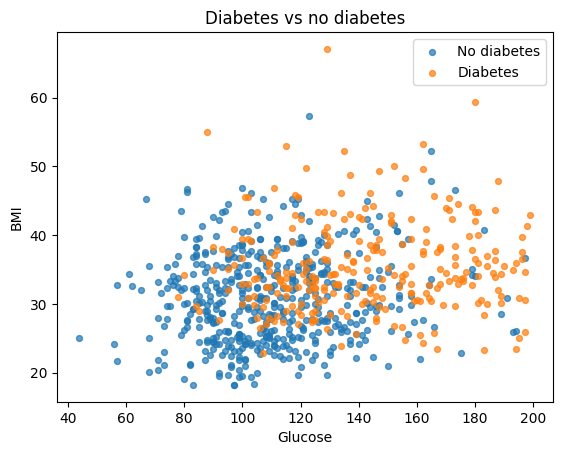

In [13]:
for label, name in [(0, 'No diabetes'), (1, 'Diabetes')]:  # one colour per class
    sub = df[df['Outcome'] == label]  # rows of this class
    plt.scatter(sub['Glucose'], sub['BMI'], label=name, s=18, alpha=0.7)  # glucose vs BMI
plt.xlabel('Glucose')
plt.ylabel('BMI')
plt.title('Diabetes vs no diabetes')
plt.legend()  # show class names
plt.show()


In [14]:
X = df.drop('Outcome', axis=1)  # 8 measurements = input
y = df['Outcome']  # diabetes yes/no = output
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)
        # 80% train / 20% test, same class ratio in both
scaler = StandardScaler()  # create the scaler
X_train_s = scaler.fit_transform(X_train)  # learn scaling from TRAIN data and apply
X_test_s = scaler.transform(X_test)  # apply the same scaling to test data
print('Train:', X_train_s.shape, '| Test:', X_test_s.shape)  # check sizes


Train: (614, 8) | Test: (154, 8)


In [15]:
svm_linear = SVC(kernel='linear', C=1.0)  # straight-line boundary
svm_linear.fit(X_train_s, y_train)  # train
svm_rbf = SVC(kernel='rbf', C=1.0, gamma='scale')  # curved boundary
svm_rbf.fit(X_train_s, y_train)  # train
print('Linear -> train:', round(svm_linear.score(X_train_s, y_train), 4), '| test:', round(svm_linear.score(X_test_s, y_test), 4))
    # accuracy
print('RBF    -> train:', round(svm_rbf.score(X_train_s, y_train), 4), '| test:', round(svm_rbf.score(X_test_s, y_test), 4))
    # accuracy
print('Support vectors (RBF):', svm_rbf.n_support_.sum(), 'of', len(X_train_s), 'training samples')
    # points that define the boundary


Linear -> train: 0.7866 | test: 0.7013
RBF    -> train: 0.8404 | test: 0.7403
Support vectors (RBF): 350 of 614 training samples


In [16]:
y_pred = svm_rbf.predict(X_test_s)  # predict test records
print('Accuracy:', round(accuracy_score(y_test, y_pred), 4))
print('Confusion Matrix:')
print(confusion_matrix(y_test, y_pred))  # rows = actual, columns = predicted
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Diabetes']))
    # precision, recall, F1 per class


Accuracy: 0.7403
Confusion Matrix:
[[84 16]
 [24 30]]
              precision    recall  f1-score   support

 No Diabetes       0.78      0.84      0.81       100
    Diabetes       0.65      0.56      0.60        54

    accuracy                           0.74       154
   macro avg       0.71      0.70      0.70       154
weighted avg       0.73      0.74      0.73       154



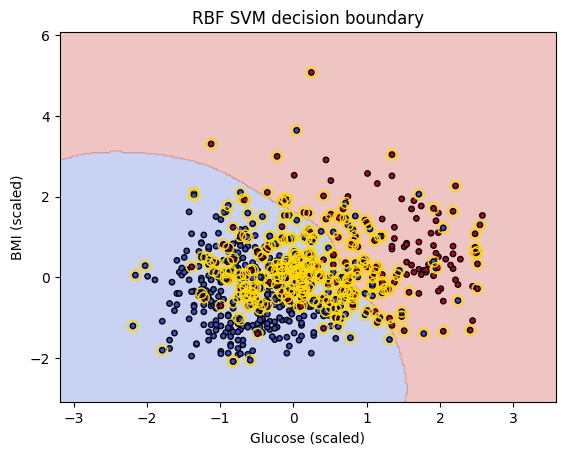

In [17]:
cols2 = [X.columns.get_loc('Glucose'), X.columns.get_loc('BMI')]
    # positions of the 2 chosen features
X2 = X_train_s[:, cols2]  # keep only these two (scaled) features
svm_2d = SVC(kernel='rbf', C=1.0, gamma='scale').fit(X2, y_train)  # SVM trained on these 2 features
xx, yy = np.meshgrid(np.linspace(X2[:, 0].min() - 1, X2[:, 0].max() + 1, 300),
    # grid of points covering the plot
                     np.linspace(X2[:, 1].min() - 1, X2[:, 1].max() + 1, 300))
Z = svm_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    # predicted class at every grid point
plt.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')  # colour the two regions
plt.scatter(X2[:, 0], X2[:, 1], c=y_train, cmap='coolwarm', edgecolors='k', s=15)  # training points
plt.scatter(*svm_2d.support_vectors_.T, s=60, facecolors='none', edgecolors='gold', linewidths=1)
    # circle the support vectors
plt.xlabel('Glucose (scaled)')
plt.ylabel('BMI (scaled)')
plt.title('RBF SVM decision boundary')
plt.show()


In [18]:
new_person = pd.DataFrame([[2, 130, 70, 25, 100, 30.5, 0.4, 35]], columns=X.columns)
    # values in the same column order
new_person_s = scaler.transform(new_person)  # scale with the SAME scaler
pred = svm_rbf.predict(new_person_s)[0]  # 0 or 1
print('Prediction:', 'Diabetes' if pred == 1 else 'No Diabetes')
print('Decision score:', round(svm_rbf.decision_function(new_person_s)[0], 3))
    # above 0 -> diabetes, below 0 -> no diabetes


Prediction: No Diabetes
Decision score: -0.367
